# M5 Forecasting Accuracy: EDA

**Contents**
1. Import libraries
2. Load sales data
3. Sales data: structure and reshape
4. Calendar: events and SNAP days
5. Sell prices: price changes and their effect on sales
6. Sales patterns: trend, seasonality, events, SNAP, zero sales, history
7. Feature summary

## Validation strategy

All data comes from `sales_train_evaluation.csv`, split by day.
Splits are always chronological: the model never sees days after the period
it is forecasting, which prevents data leakage. Days are never split at random.

| Period | Days | Role |
|---|---|---|
| Training | `d_1` – `d_1913` | Fit the model during development |
| Validation | `d_1914` – `d_1941` | Measure WRMSSE on known sales |
| Evaluation | `d_1942` – `d_1969` | Final forecast (sales unknown) |

The work runs in two stages:

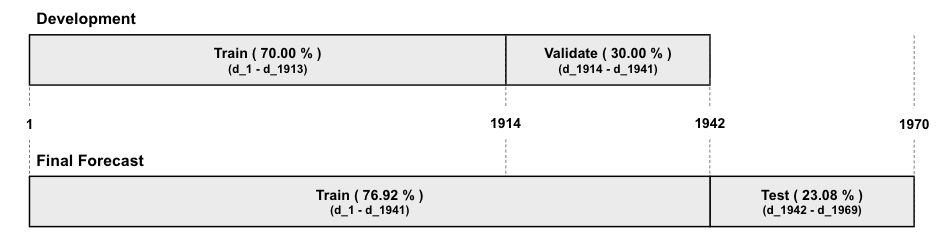

1. **Development.** Train on `d_1` – `d_1913` and forecast `d_1914` – `d_1941`.
   Compare the forecast with actual sales to compute WRMSSE.
   Feature and parameter changes are judged on this score.
2. **Final forecast.** Retrain on all data up to `d_1941` with the chosen setup,
   then forecast `d_1942` – `d_1969`. The most recent 28 days are the closest
   to the forecast period, so they are included in the final training.

Before training, each table is joined into one row per product, store and day:

- `sales_train_evaluation.csv` is reshaped from wide to long format
  (one column per day becomes one row per day).
- `calendar.csv` is joined on `d`.
- `sell_prices.csv` is joined on `store_id`, `item_id` and `wm_yr_wk`.
  Rows with no price are dropped, since the product was not yet on sale.

**Possible improvement:** A single 28-day window may fall on an unusual period.
Walk-forward validation over several windows (for example, ending at `d_1885`,
`d_1913` and `d_1941`) would give a more reliable estimate.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

# สีประจำหมวดสินค้า ใช้ชุดเดียวกันทุกกราฟ
CAT_COLORS = {"FOODS": "#2a78d6", "HOBBIES": "#eb6834", "HOUSEHOLD": "#1baf7a"}

## 2. Load Sales Data

In [2]:
sales_df = pd.read_csv("m5-data/sales_train_evaluation.csv")
sales_df.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


## 3. Sales Data: Structure and Reshape

### 3.1 Structure: 30,490 rows × 1,947 columns
- 1 แถว = สินค้า 1 รายการใน 1 ร้าน (3,049 items × 10 stores = 30,490)
- 6 columns แรกเป็น ID: `id`, `item_id`, `dept_id`, `cat_id`, `store_id`, `state_id`
- `d_1` – `d_1941` คือยอดขายรายวัน รวม 1,941 columns

In [3]:
sales_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Columns: 1947 entries, id to d_1941
dtypes: int64(1941), str(6)
memory usage: 452.9 MB


### 3.2 Melt `d_1` – `d_1941` into long format
- `d` ใช้สำหรับ join กับ `calendar.csv`
- `day` เป็นตัวเลขของวัน ใช้เรียงลำดับเวลา
- แปลง ID columns เป็น `category` เพื่อลด RAM เพราะตารางมีราว 59 ล้านแถว

In [4]:
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
sales_df[id_cols] = sales_df[id_cols].astype("category")

long_df = sales_df.melt(id_vars=id_cols, var_name="d", value_name="sales")
long_df["day"] = long_df["d"].str[2:].astype(int)
long_df.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,day
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1


In [5]:
long_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59181090 entries, 0 to 59181089
Data columns (total 9 columns):
 #   Column    Dtype   
---  ------    -----   
 0   id        category
 1   item_id   category
 2   dept_id   category
 3   cat_id    category
 4   store_id  category
 5   state_id  category
 6   d         str     
 7   sales     int64   
 8   day       int64   
dtypes: category(6), int64(2), str(1)
memory usage: 1.8 GB


ทุกวันมี 30,490 แถวเท่ากัน แปลว่าสินค้าทุกรายการมีแถวครบทุกวัน
รวมถึงช่วงก่อนเริ่มวางขาย ซึ่งยอดขายเป็น 0 แถวเหล่านี้จะถูกตัดออกตอน join กับ `sell_prices.csv`

In [6]:
long_df.groupby("day").size().agg(["min", "max"])

min    30490
max    30490
dtype: int64

## 4. Calendar: Events and SNAP Days

In [7]:
calendar_df = pd.read_csv("m5-data/calendar.csv", parse_dates=["date"])
calendar_df.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [8]:
calendar_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1969 non-null   datetime64[us]
 1   wm_yr_wk      1969 non-null   int64         
 2   weekday       1969 non-null   str           
 3   wday          1969 non-null   int64         
 4   month         1969 non-null   int64         
 5   year          1969 non-null   int64         
 6   d             1969 non-null   str           
 7   event_name_1  162 non-null    str           
 8   event_type_1  162 non-null    str           
 9   event_name_2  5 non-null      str           
 10  event_type_2  5 non-null      str           
 11  snap_CA       1969 non-null   int64         
 12  snap_TX       1969 non-null   int64         
 13  snap_WI       1969 non-null   int64         
dtypes: datetime64[us](1), int64(7), str(6)
memory usage: 215.5 KB


### 4.1 Events: drop `event_name_2`
`event_name_2` ตัดออกได้ เพราะ

- มีข้อมูลเพียง 5 วัน จากทั้งหมด 1,969 วัน (น้อยกว่า 0.25%)
  ซึ่งเป็นวันที่มีอีเวนต์สองรายการตรงกันโดยบังเอิญ
- อีเวนต์ทุกรายการใน `event_name_2` ปรากฏใน `event_name_1` ในปีอื่นอยู่แล้ว
  โมเดลจึงยังเรียนรู้ผลของอีเวนต์เหล่านั้นได้จาก `event_name_1`
- ข้อมูลที่มีเพียงไม่กี่วัน ไม่พอให้โมเดลเรียนรู้รูปแบบได้อย่างน่าเชื่อถือ
  และยังเพิ่มคอลัมน์ที่ต้องใช้ RAM ในตารางราว 59 ล้านแถว

In [9]:
event_counts = (
    calendar_df[["event_name_1", "event_name_2"]]
    .melt(var_name="column", value_name="event")
    .dropna()
    .groupby(["event", "column"], observed=True)
    .size()
    .reset_index(name="days")
)

order = event_counts.groupby("event")["days"].sum().sort_values().index.tolist()

fig = px.bar(
    event_counts,
    x="days", y="event", color="column",
    orientation="h",
    category_orders={"event": order},
    title="Event days by column",
    labels={"days": "Number of days", "event": "", "column": ""},
    height=800,
)
fig.show()

In [10]:
n = calendar_df["event_name_2"].notna().sum()
print(f"Days with event_name_2: {n} ({n / len(calendar_df):.2%})")

# อีเวนต์ใน event_name_2 ที่ไม่เคยอยู่ใน event_name_1 (set ว่าง = ไม่มี)
set(calendar_df["event_name_2"].dropna()) - set(calendar_df["event_name_1"].dropna())

Days with event_name_2: 5 (0.25%)


set()

In [11]:
calendar_df = calendar_df[[
    "d", "date", "wm_yr_wk", "wday", "month", "year",
    "event_name_1", "event_type_1", "snap_CA", "snap_TX", "snap_WI",
]]

# ลดขนาด dtype ก่อน join กับตาราง 59 ล้านแถว
for c in ["event_name_1", "event_type_1"]:
    calendar_df[c] = calendar_df[c].astype("category")
for c in ["wday", "month", "snap_CA", "snap_TX", "snap_WI"]:
    calendar_df[c] = calendar_df[c].astype("int8")
calendar_df["year"] = calendar_df["year"].astype("int16")
calendar_df.head()

,d,date,wm_yr_wk,wday,month,year,event_name_1,event_type_1,snap_CA,snap_TX,snap_WI
0,d_1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
1,d_2,2011-01-30,11101,2,1,2011,NaN,NaN,0,0,0
2,d_3,2011-01-31,11101,3,1,2011,NaN,NaN,0,0,0
3,d_4,2011-02-01,11101,4,2,2011,NaN,NaN,1,1,0
4,d_5,2011-02-02,11101,5,2,2011,NaN,NaN,1,0,1


### 4.2 Join sales with calendar
- `calendar.csv` มี 1 แถวต่อวัน จึงเป็นการ join แบบ many-to-one จำนวนแถวต้องเท่าเดิม
- หลัง join ไม่ต้องใช้ `d` แล้ว เพราะมี `day` และ `date` อยู่

In [12]:
merge_df = long_df.merge(calendar_df, on="d", how="left", validate="many_to_one")
assert len(merge_df) == len(long_df)
merge_df = merge_df.drop(columns=["d"])

# คืน RAM: ไม่ต้องใช้ตารางก่อน join แล้ว
del sales_df, long_df
merge_df.head()

,id,item_id,dept_id,cat_id,store_id,state_id,sales,day,date,wm_yr_wk,wday,month,year,event_name_1,event_type_1,snap_CA,snap_TX,snap_WI
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0


### 4.3 SNAP days
- SNAP ย่อมาจาก Supplemental Nutrition Assistance Program
- คือวันที่รัฐบาลสหรัฐฯ จ่ายเงินช่วยเหลือค่าอาหารให้ครอบครัวรายได้น้อย
- แต่ละรัฐมีวัน SNAP ของตัวเอง และตกวันที่เดิมทุกเดือน

In [13]:
snap_cols = ["snap_CA", "snap_TX", "snap_WI"]
snap_by_dom = (
    calendar_df.assign(day_of_month=calendar_df["date"].dt.day)
    .groupby("day_of_month")[snap_cols].mean()
    .T.rename(index=lambda c: c.replace("snap_", ""))
)

fig = go.Figure(go.Heatmap(
    z=snap_by_dom.values, x=snap_by_dom.columns, y=snap_by_dom.index,
    colorscale=[[0, "#eef1f5"], [1, "#2a6fdb"]], showscale=False,
    xgap=2, ygap=2,
    hovertemplate="%{y}, day %{x}: %{z:.0%} SNAP<extra></extra>",
))
fig.update_xaxes(dtick=1, title="Day of month", showgrid=False)
fig.update_yaxes(title=None, autorange="reversed", showgrid=False)
fig.update_layout(
    title="SNAP days by state (blue = SNAP day)",
    height=260, plot_bgcolor="white",
)
fig.show()

ร้านแต่ละแห่งได้รับผลจาก SNAP ของรัฐตัวเองเท่านั้น
จึงรวม 3 columns เป็น `snap` column เดียว โดยใช้ค่าของรัฐที่ร้านตั้งอยู่

In [14]:
merge_df["snap"] = np.select(
    [merge_df["state_id"] == "CA", merge_df["state_id"] == "TX"],
    [merge_df["snap_CA"], merge_df["snap_TX"]],
    default=merge_df["snap_WI"],
).astype("int8")

merge_df = merge_df.drop(columns=snap_cols)

## 5. Sell Prices

In [15]:
prices_df = pd.read_csv("m5-data/sell_prices.csv")
prices_df.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [16]:
prices_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6841121 entries, 0 to 6841120
Data columns (total 4 columns):
 #   Column      Dtype  
---  ------      -----  
 0   store_id    str    
 1   item_id     str    
 2   wm_yr_wk    int64  
 3   sell_price  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 208.8 MB


### 5.1 Price changes
ราคาเป็นรายสัปดาห์ (`wm_yr_wk`) ต่อสินค้าต่อร้าน
ดูว่าแต่ละหมวดเปลี่ยนราคาบ่อยแค่ไหน

In [17]:
prices_df = prices_df.sort_values(["store_id", "item_id", "wm_yr_wk"]).reset_index(drop=True)
prices_df["cat_id"] = prices_df["item_id"].str.split("_").str[0]

price_diff = prices_df.groupby(["store_id", "item_id"])["sell_price"].diff()
prices_df["price_changed"] = price_diff.notna() & price_diff.ne(0)

price_summary = (
    prices_df.groupby("cat_id")
    .agg(
        weeks_with_change=("price_changed", "mean"),
        weeks=("sell_price", "size"),
    )
    .join(
        prices_df.groupby(["cat_id", "store_id", "item_id"])["sell_price"]
        .nunique().groupby("cat_id").median().rename("median_distinct_prices")
    )
)
price_summary.style.format({"weeks_with_change": "{:.1%}", "weeks": "{:,}"})

,weeks_with_change,weeks,median_distinct_prices
cat_id,,,
FOODS,1.6%,"3,181,789",3.000000
HOBBIES,0.7%,"1,283,905",2.000000
HOUSEHOLD,0.8%,"2,375,427",2.000000


**สรุป:** ราคาเปลี่ยนไม่บ่อย มีเพียง 0.7–1.6% ของสัปดาห์ที่ราคาต่างจากสัปดาห์ก่อน
ตลอด 5 ปี สินค้าส่วนใหญ่มีราคาแค่ 2–3 ระดับ (FOODS เปลี่ยนบ่อยที่สุด)
ดังนั้นการเปลี่ยนราคาแต่ละครั้งเป็นเหตุการณ์ที่หายาก ซึ่งอาจมีความหมายต่อยอดขาย

### 5.2 Join sales with prices
- join ด้วย `store_id`, `item_id`, `wm_yr_wk` ซึ่ง 1 สินค้า 1 ร้าน มี 1 ราคาต่อสัปดาห์
- แถวที่ไม่มีราคา = สินค้ายังไม่วางขาย จึงตัดออก
- ก่อนตัด เช็กก่อนว่ามีช่วงที่ไม่มีราคา *หลัง* สินค้าเริ่มขายแล้วหรือไม่

In [18]:
# ใช้ categories ชุดเดียวกับ merge_df เพื่อให้ join ได้โดยไม่ต้องแปลงกลับเป็น str
for col in ["store_id", "item_id"]:
    prices_df[col] = pd.Categorical(prices_df[col], categories=merge_df[col].cat.categories)
prices_df["sell_price"] = prices_df["sell_price"].astype("float32")

merge_df = merge_df.merge(
    prices_df[["store_id", "item_id", "wm_yr_wk", "sell_price"]],
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left", validate="many_to_one",
)
has_price = merge_df["sell_price"].notna()
print(f"Rows without price: {(~has_price).mean():.1%}")

Rows without price: 20.8%


In [19]:
first_price_day = merge_df["day"].where(has_price).groupby(merge_df["id"], observed=True).transform("min")
gap = ~has_price & (merge_df["day"] > first_price_day)

print(f"Rows without price after first sale: {gap.sum():,}")
print(f"Sales on rows without price: {merge_df.loc[~has_price, 'sales'].sum():,}")

Rows without price after first sale: 0


Sales on rows without price: 0


**สรุป:** มี 20.8% ของแถวที่ไม่มีราคา ทั้งหมดเป็นช่วงก่อนสินค้าวางขาย
(ไม่มีช่วงที่ราคาหายไปกลางทาง) และแถวเหล่านี้มียอดขายเป็น 0 ทั้งหมด
จึงตัดออกได้โดยไม่เสียข้อมูล ตารางลดจาก 59.2 ล้านเหลือ 46.9 ล้านแถว

In [20]:
merge_df = merge_df[has_price].reset_index(drop=True)
del prices_df, price_diff, has_price, first_price_day, gap
merge_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 46881677 entries, 0 to 46881676
Data columns (total 17 columns):
 #   Column        Dtype         
---  ------        -----         
 0   id            category      
 1   item_id       category      
 2   dept_id       category      
 3   cat_id        category      
 4   store_id      category      
 5   state_id      category      
 6   sales         int64         
 7   day           int64         
 8   date          datetime64[us]
 9   wm_yr_wk      int64         
 10  wday          int8          
 11  month         int8          
 12  year          int16         
 13  event_name_1  category      
 14  event_type_1  category      
 15  snap          int8          
 16  sell_price    float32       
dtypes: category(8), datetime64[us](1), float32(1), int16(1), int64(3), int8(3)
memory usage: 2.2 GB


### 5.3 Sales around price changes
**คำถาม:** เมื่อราคาเปลี่ยน ยอดขายเปลี่ยนไปเท่าไร

ข้อมูลไม่มีราคาปกติหรือธงโปรโมชัน จึงไม่นิยามว่าราคาไหนคือ "ลดราคา"
แต่ใช้เฉพาะสิ่งที่เกิดขึ้นจริง คือสัปดาห์ที่ราคาเปลี่ยน แล้วเทียบสินค้าตัวเดียวกันในร้านเดียวกัน

- **ก่อน:** ยอดขายเฉลี่ยต่อสัปดาห์ 4 สัปดาห์สุดท้ายที่ราคาเดิม (ราคาเดิมต้องคงที่อย่างน้อย 4 สัปดาห์)
- **หลัง:** ยอดขายเฉลี่ยต่อสัปดาห์ช่วงแรกที่ราคาใหม่ (สูงสุด 4 สัปดาห์)
- ใช้เฉพาะสัปดาห์ที่มีข้อมูลครบ 7 วัน และตัดกรณีที่ยอดขายก่อนเปลี่ยนเป็น 0

In [21]:
WINDOW = 4  # weeks
key = ["store_id", "item_id"]

weekly = (
    merge_df.groupby(key + ["cat_id", "wm_yr_wk"], observed=True)
    .agg(units=("sales", "sum"), price=("sell_price", "first"), days=("sales", "size"))
    .reset_index()
)
weekly = weekly[weekly["days"] == 7].reset_index(drop=True)

# run = ช่วงสัปดาห์ติดกันที่ราคาเท่าเดิม
price_changed = weekly.groupby(key, observed=True)["price"].diff().fillna(0).ne(0)
weekly["run"] = price_changed.groupby([weekly["store_id"], weekly["item_id"]], observed=True).cumsum()

by_run = weekly.groupby(key + ["run"], observed=True)
runs = by_run.agg(cat_id=("cat_id", "first"), price=("price", "first"), weeks=("price", "size"))
runs["units_first"] = by_run.head(WINDOW).groupby(key + ["run"], observed=True)["units"].mean()
runs["units_last"] = by_run.tail(WINDOW).groupby(key + ["run"], observed=True)["units"].mean()
runs = runs.reset_index()

by_item = runs.groupby(key, observed=True)
prev = by_item[["price", "weeks", "units_last"]].shift()
price_events = pd.DataFrame({
    "cat_id": runs["cat_id"],
    "old_price": prev["price"], "new_price": runs["price"], "next_price": by_item["price"].shift(-1),
    "old_weeks": prev["weeks"], "before": prev["units_last"], "after": runs["units_first"],
})
price_events = price_events[
    price_events["old_price"].notna()
    & (price_events["old_weeks"] >= WINDOW)
    & (price_events["before"] > 0)
].reset_index(drop=True)

price_events["price_chg"] = price_events["new_price"] / price_events["old_price"] - 1
price_events["sales_chg"] = price_events["after"] / price_events["before"] - 1
price_events["price_band"] = pd.cut(
    price_events["price_chg"], [-1, -0.3, -0.1, 0, 0.1, 0.3, float("inf")],
    labels=["Down ≥30%", "Down 10–30%", "Down 0–10%", "Up 0–10%", "Up 10–30%", "Up >30%"],
)
del weekly, price_changed, by_run, runs, by_item, prev
print(f"Price change events: {len(price_events):,}")

Price change events: 51,409


In [22]:
def summarize_events(events):
    by_band = events.groupby(["price_band", "cat_id"], observed=True)["sales_chg"]
    return pd.concat({
        "median sales change": by_band.median().unstack(),
        "share with higher sales": by_band.apply(lambda s: (s > 0).mean()).unstack(),
        "events": by_band.size().unstack(),
    }, axis=1)

summarize_events(price_events).style.format("{:+.1%}", subset=["median sales change"]) \
    .format("{:.0%}", subset=["share with higher sales"]).format("{:,}", subset=["events"])

**เช็กเพิ่ม:** การลดราคาแรงเป็นการล้างสต็อกก่อนเลิกขายหรือไม่
- `is_last_price` = ราคาใหม่เป็นราคาสุดท้ายของสินค้านั้น
- `returns_to_old` = ราคาถัดไปกลับไปเท่าราคาเดิม (ลดชั่วคราว)

In [23]:
price_events.assign(
    is_last_price=price_events["next_price"].isna(),
    returns_to_old=price_events["next_price"] == price_events["old_price"],
).groupby("price_band", observed=True)[["is_last_price", "returns_to_old"]].mean().style.format("{:.0%}")

,is_last_price,returns_to_old
price_band,,
Down ≥30%,1%,92%
Down 10–30%,11%,58%
Down 0–10%,37%,23%
Up 0–10%,35%,11%
Up 10–30%,31%,18%
Up >30%,12%,30%


**เช็กเพิ่ม:** ดูเฉพาะสินค้าที่ขายเกิน 10 ชิ้นต่อสัปดาห์ก่อนเปลี่ยนราคา
สินค้าขายน้อยมีค่ามัธยฐานเป็น 0% บ่อย เพราะยอดขายเปลี่ยนจาก 1 เป็น 1 ชิ้น

In [24]:
summarize_events(price_events[price_events["before"] > 10]).style \
    .format("{:+.1%}", subset=["median sales change"]) \
    .format("{:.0%}", subset=["share with higher sales"]).format("{:,}", subset=["events"])

**สรุป:** จากการเปลี่ยนราคาจริง 51,409 ครั้ง
- **ข้อมูลไม่ได้แสดงว่าลดราคาแล้วขายเพิ่มอย่างชัดเจน** มีเพียงการลดเล็กน้อย (0–10%) ที่ยอดขายเพิ่มราว 7–9%
- **ลดราคาแรง (≥ 30%) ยอดขายกลับลดลง** (มัธยฐาน −7 ถึง −11%) และยอดขายเพิ่มเพียงราว 40% ของเหตุการณ์
- การลดแรงไม่ใช่การล้างสต็อก: เป็นราคาสุดท้ายเพียง 1% และ 92% กลับไปราคาเดิม (ลดชั่วคราว)
  ข้อมูลชุดนี้ไม่บอกว่าทำไมยอดขายไม่เพิ่ม จึงยังสรุปสาเหตุไม่ได้
- **ราคาไม่ใช่ปัจจัยเดียว:** ในสินค้าที่ขายเกิน 10 ชิ้นต่อสัปดาห์ แม้แต่ตอนขึ้นราคา 0–10% ยอดขายก็ลดลงราว 8%
  แปลว่ามีปัจจัยอื่นปนอยู่ เช่น ฤดูกาล หรือสัปดาห์ที่ขายดีเป็นพิเศษมักตามด้วยสัปดาห์ที่กลับมาใกล้ค่าเฉลี่ย

**ผลต่อการทำโมเดล:** ไม่ตั้งสมมติฐานล่วงหน้าว่าราคามีผลทางไหน
แต่ใส่ข้อเท็จจริงของราคาเป็น feature ให้โมเดลเรียนรู้เอง เช่น ราคาปัจจุบัน,
% ที่เปลี่ยนจากสัปดาห์ก่อน, และจำนวนสัปดาห์ที่ราคานี้คงที่มา

## 6. Sales Patterns
ใช้ตารางหลัง join ครบทุกตาราง และตัดแถวก่อนสินค้าวางขายแล้ว (46.9 ล้านแถว)
ค่าเฉลี่ยในส่วนนี้คือ **ยอดขายเฉลี่ยต่อสินค้าต่อวัน** เฉพาะสินค้าที่วางขายอยู่

In [25]:
del price_events
merge_df["day_name"] = merge_df["date"].dt.day_name().astype("category")

# ยอดขายรวมรายวันแยกหมวด ใช้ในหลาย section ด้านล่าง
daily = (
    merge_df.groupby(["date", "cat_id"], observed=True)
    .agg(sales=("sales", "sum"), items=("sales", "size"),
         day_name=("day_name", "first"), event=("event_name_1", "first"))
    .reset_index()
)
daily["per_item"] = daily["sales"] / daily["items"]
daily.head()

,date,cat_id,sales,items,day_name,event,per_item
0,2011-01-29,FOODS,23178,5447,Saturday,NaN,4.255186
1,2011-01-29,HOBBIES,3764,1853,Saturday,NaN,2.031301
2,2011-01-29,HOUSEHOLD,5689,3632,Saturday,NaN,1.566355
3,2011-01-30,FOODS,22758,5447,Sunday,NaN,4.178080
4,2011-01-30,HOBBIES,3357,1853,Sunday,NaN,1.811657


### 6.1 Trend
ยอดขายรวมรายวันแยกหมวด และจำนวนสินค้าที่วางขาย

In [26]:
fig = px.line(
    daily, x="date", y="sales", color="cat_id", color_discrete_map=CAT_COLORS,
    labels={"date": "", "sales": "Units sold per day", "cat_id": "Category"},
    title="Daily units sold by category",
)
fig.update_traces(line_width=1.5)
fig.show()

trend = daily.assign(year=daily["date"].dt.year).query("year < 2016").groupby(["year", "cat_id"], observed=True)[["sales", "items", "per_item"]].mean()
trend.unstack().style.format("{:,.2f}")

**สรุป:**
- ยอดขายรวมเพิ่มขึ้นทุกปี แต่**ส่วนใหญ่มาจากจำนวนสินค้าที่วางขายเพิ่มขึ้น** (FOODS เพิ่มจาก ~7,000 เป็น ~14,000 รายการ)
- ยอดขาย**ต่อสินค้า**กลับลดลง เช่น FOODS ลดจาก 2.65 เหลือ 1.74 ชิ้นต่อวัน เพราะสินค้าที่เพิ่งวางขายมักยังขายได้น้อย
- ทุกปีมีวันที่ยอดขายเป็น 0 เกือบทั้งหมด คือวัน Christmas (ร้านปิด) ดูได้ใน 6.3
- ยอดขายต่อสินค้าจึงขึ้นกับว่าสินค้าวางขายมานานแค่ไหน ซึ่งเป็น feature ที่ควรลองใส่

### 6.2 Day of week and month
ดัชนี = ยอดขายเฉลี่ยในวันนั้น / ยอดขายเฉลี่ยทั้งหมดของหมวดนั้น (1.0 = เท่าค่าเฉลี่ย)

In [27]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
cat_mean = merge_df.groupby("cat_id", observed=True)["sales"].mean()

def seasonal_index(col):
    m = merge_df.groupby(["cat_id", col], observed=True)["sales"].mean()
    return m.div(cat_mean, level="cat_id").rename("index").reset_index()

weekday_idx = seasonal_index("day_name")
fig = px.bar(
    weekday_idx, x="day_name", y="index", color="cat_id", barmode="group",
    color_discrete_map=CAT_COLORS, category_orders={"day_name": weekday_order},
    labels={"day_name": "", "index": "Sales index (1 = category average)", "cat_id": "Category"},
    title="Sales by day of week",
)
fig.add_hline(y=1, line_dash="dot", line_color="gray")
fig.show()

month_idx = seasonal_index("month")
fig = px.line(
    month_idx, x="month", y="index", color="cat_id", markers=True,
    color_discrete_map=CAT_COLORS,
    labels={"month": "Month", "index": "Sales index (1 = category average)", "cat_id": "Category"},
    title="Sales by month",
)
fig.update_xaxes(dtick=1)
fig.add_hline(y=1, line_dash="dot", line_color="gray")
fig.show()

**สรุป:**
- **วันในสัปดาห์มีผลชัดเจน:** เสาร์–อาทิตย์ขายมากกว่าค่าเฉลี่ย 11–26% ส่วนอังคาร–พฤหัสต่ำกว่า 10–15% รูปแบบเหมือนกันทุกหมวด
- **เดือนมีผลน้อยกว่า:** ต่างจากค่าเฉลี่ยไม่เกินราว ±10% โดยพฤศจิกายน–มกราคมต่ำกว่าค่าเฉลี่ยทุกหมวด
  (ธันวาคมรวมวัน Christmas ที่ร้านปิดไว้ด้วย)

### 6.3 Events
เทียบยอดขายวันที่มี event กับ **วันเดียวกันของสัปดาห์** ใน 2 สัปดาห์ก่อนและหลัง (±7, ±14 วัน) ที่ไม่มี event
เพื่อตัดผลของวันในสัปดาห์และฤดูกาลออก

In [28]:
total = daily.groupby("date", observed=True).agg(sales=("sales", "sum"), items=("items", "sum"), event=("event", "first"))
total["per_item"] = total["sales"] / total["items"]
no_event = total["per_item"].where(total["event"].isna())

baseline = pd.concat([no_event.shift(k) for k in (-14, -7, 7, 14)], axis=1).mean(axis=1)
event_effect = (
    (total["per_item"] / baseline - 1)[total["event"].notna()]
    .groupby(total["event"], observed=True).median()
    .sort_values().rename("effect").reset_index()
)

fig = px.bar(
    event_effect, x="effect", y="event", orientation="h",
    color_discrete_sequence=[CAT_COLORS["FOODS"]],
    labels={"effect": "Sales vs same weekday, ±2 weeks (median across years)", "event": ""},
    title="Sales on event days",
    height=800,
)
fig.update_xaxes(tickformat="+.0%")
fig.add_vline(x=0, line_color="gray")
fig.show()

**สรุป:** (เทียบกับวันเดียวกันของสัปดาห์ ±2 สัปดาห์, ค่ามัธยฐานของแต่ละปี)
- **Christmas −100%:** ร้านปิด ยอดขายเป็น 0 ทุกปี โมเดลต้องรู้วันนี้
- **ยอดขายลดลงชัด:** Thanksgiving −28%, NewYear −22%, Mother's day / Easter / Father's day ราว −11%
- **ยอดขายเพิ่มขึ้นชัด:** LaborDay +26%, VeteransDay +12%, ColumbusDay +10%, NBAFinalsStart +10%
- อีกราวครึ่งหนึ่งของ event ต่างจากวันปกติไม่ถึง ±5%
- แต่ละ event มีข้อมูลแค่ราว 5 ครั้ง (1 ครั้งต่อปี) ตัวเลขจึงยังมีความไม่แน่นอนสูง

ผลของ event ต่างกันไปทั้งทิศทางและขนาด จึงควรใช้ `event_name_1` (ชื่อ event) มากกว่า `event_type_1` (ประเภท)

### 6.4 SNAP effect
ยอดขายเฉลี่ยวันที่เป็น SNAP เทียบกับวันที่ไม่ใช่ SNAP (ตัดแถวก่อนวางขายแล้ว)

In [29]:
snap_sales = (
    merge_df.groupby(["cat_id", "snap"], observed=True)["sales"].mean()
    .unstack()
    .rename(columns={0: "non_snap", 1: "snap"})
)
snap_sales["lift"] = snap_sales["snap"] / snap_sales["non_snap"] - 1
snap_sales.style.format({"non_snap": "{:.3f}", "snap": "{:.3f}", "lift": "{:+.1%}"})

snap,non_snap,snap,lift
cat_id,,,
FOODS,1.992,2.341,+17.5%
HOBBIES,0.703,0.722,+2.8%
HOUSEHOLD,0.896,0.930,+3.8%


**สรุป:** ผลเหมือนก่อนตัดแถวที่ยังไม่วางขาย SNAP ส่งผลชัดกับ `FOODS` (+17.5%)
แต่แทบไม่มีผลกับ `HOBBIES` (+2.8%) และ `HOUSEHOLD` (+3.8%)
ซึ่งสอดคล้องกับที่เงิน SNAP ใช้ซื้อได้เฉพาะอาหาร จึงควรใช้ `snap` เป็น feature

### 6.5 Zero sales
สัดส่วนวันที่ขายไม่ได้เลย บอกว่ายอดขายเป็นแบบ intermittent (ขายเป็นช่วง ๆ) แค่ไหน

In [30]:
zero_share = (merge_df["sales"] == 0).groupby([merge_df["cat_id"], merge_df["id"]], observed=True).mean()
zero_summary = pd.DataFrame({
    "zero_days": (merge_df["sales"] == 0).groupby(merge_df["cat_id"], observed=True).mean(),
    "median_item_zero_days": zero_share.groupby("cat_id", observed=True).median(),
    "items_zero_over_50pct": (zero_share > 0.5).groupby("cat_id", observed=True).mean(),
})
zero_summary.style.format("{:.0%}")

,zero_days,median_item_zero_days,items_zero_over_50pct
cat_id,,,
FOODS,51%,54%,56%
HOBBIES,72%,78%,85%
HOUSEHOLD,65%,70%,74%


In [31]:
fig = px.histogram(
    zero_share.rename("zero_share").reset_index(), x="zero_share", color="cat_id",
    facet_row="cat_id", color_discrete_map=CAT_COLORS, nbins=50,
    labels={"zero_share": "Share of days with zero sales (per item-store)", "cat_id": "Category"},
    title="How often each item-store sells nothing",
    height=600,
)
fig.update_xaxes(tickformat=".0%")
fig.update_layout(showlegend=False)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

**สรุป:**
- **วันที่ขายไม่ได้เลยมีมากกว่าครึ่ง:** 51% ของวันใน FOODS, 65% ใน HOUSEHOLD และ 72% ใน HOBBIES
- สินค้า-ร้านส่วนใหญ่ (56–85%) ขายไม่ได้เลยเกินครึ่งหนึ่งของวันที่วางขาย
- ยอดขายจึงเป็นแบบ intermittent (ขายเป็นช่วง ๆ มีค่า 0 มาก)
  loss แบบ MSE ปกติไม่ได้ออกแบบมาสำหรับข้อมูลแบบนี้ ควรลอง loss ที่รองรับค่า 0 มาก ๆ เช่น Tweedie หรือ Poisson

### 6.6 Sales history
เราต้องพยากรณ์ล่วงหน้า 28 วัน ข้อมูลที่ใช้ได้แน่นอนคือยอดขายตั้งแต่ 28 วันก่อนขึ้นไป
ดูว่ายอดขายในอดีตสัมพันธ์กับยอดขายวันนี้แค่ไหน (Pearson correlation แยกหมวด)
- `lag_7`, `lag_28`: ยอดขายเมื่อ 7 / 28 วันก่อน
- `mean_7_lag_28`, `mean_28_lag_28`: ค่าเฉลี่ย 7 / 28 วัน ที่สิ้นสุดเมื่อ 28 วันก่อน

In [32]:
# แถวของแต่ละสินค้าเรียงตามวันและไม่มีวันขาดหาย (เช็กแล้วใน 5.2) จึง shift ตามแถวได้
by_id = merge_df.groupby("id", observed=True)["sales"]
csum = by_id.cumsum()
by_csum = csum.groupby(merge_df["id"], observed=True)

history = pd.DataFrame({
    "cat_id": merge_df["cat_id"],
    "sales": merge_df["sales"],
    "lag_7": by_id.shift(7),
    "lag_28": by_id.shift(28),
    "mean_7_lag_28": (by_csum.shift(28) - by_csum.shift(35)) / 7,
    "mean_28_lag_28": (by_csum.shift(28) - by_csum.shift(56)) / 28,
}).dropna()
del by_id, csum, by_csum

history_corr = history.groupby("cat_id", observed=True).corr()["sales"].unstack().drop(columns="sales")
del history
history_corr.style.format("{:.2f}")

,lag_7,lag_28,mean_7_lag_28,mean_28_lag_28
cat_id,,,,
FOODS,0.74,0.69,0.74,0.75
HOBBIES,0.38,0.37,0.52,0.56
HOUSEHOLD,0.61,0.58,0.68,0.70


**สรุป:**
- ยอดขายในอดีตสัมพันธ์กับยอดขายวันนี้ชัดเจนใน FOODS (0.69–0.75) และ HOUSEHOLD (0.58–0.70) แต่ต่ำกว่าใน HOBBIES (0.37–0.56)
- **ค่าเฉลี่ยหลายวันสัมพันธ์ดีกว่ายอดขายวันเดียว** เช่น `mean_28_lag_28` ดีกว่า `lag_28` ทุกหมวด
  เพราะการเฉลี่ยช่วยลดผลของวันที่เป็น 0 แบบสุ่ม
- `lag_7` ดีกว่า `lag_28` เล็กน้อย แต่ใช้ได้เฉพาะเมื่อพยากรณ์ทีละวัน (recursive) ถ้าพยากรณ์ 28 วันพร้อมกัน ต้องใช้ lag ≥ 28

## 7. Feature Summary
สรุปจาก EDA ทั้งหมด ✅ = มีหลักฐานว่ามีผลต่อยอดขาย, ⚠️ = ควรลองใช้ แต่หลักฐานไม่ชัด, ❌ = ไม่ใช้

| Feature | ใช้? | เหตุผล | Section |
|---|---|---|---|
| `wday` / day of week | ✅ | เสาร์–อาทิตย์ +11–26%, อังคาร–พฤหัส −10–15% ทุกหมวด | 6.2 |
| `event_name_1` | ✅ | Christmas −100% (ร้านปิด), Thanksgiving −28%, LaborDay +26% แต่ละ event ต่างกันมาก | 6.3 |
| `snap` (ของรัฐที่ร้านตั้งอยู่) | ✅ | FOODS +17.5%, หมวดอื่น +3–4% | 4.3, 6.4 |
| `cat_id`, `dept_id`, `store_id`, `state_id`, `item_id` | ✅ | ยอดขายต่อสินค้า ผลของ SNAP และสัดส่วนวันที่ขายได้ 0 ต่างกันมากในแต่ละหมวด | 6.1, 6.4, 6.5 |
| Rolling mean ของยอดขาย (สิ้นสุด ≥ 28 วันก่อน) | ✅ | correlation 0.56–0.75 สูงกว่า lag วันเดียวทุกหมวด | 6.6 |
| `lag_28` | ✅ | correlation 0.37–0.69 | 6.6 |
| `lag_7` และ lag อื่นที่ < 28 | ⚠️ | สัมพันธ์ดีกว่าเล็กน้อย แต่ใช้ได้เฉพาะเมื่อพยากรณ์ทีละวัน (recursive) | 6.6 |
| `month` | ⚠️ | ต่างจากค่าเฉลี่ยไม่เกินราว ±10% | 6.2 |
| จำนวนวันตั้งแต่สินค้าเริ่มวางขาย | ⚠️ | ยอดขายต่อสินค้าลดลงเมื่อมีสินค้าใหม่เพิ่ม แต่ยังไม่ได้วัดตรง ๆ ตามอายุสินค้า | 6.1 |
| `sell_price`, % ราคาเปลี่ยนจากสัปดาห์ก่อน, จำนวนสัปดาห์ที่ราคาคงที่ | ⚠️ | ราคาเปลี่ยนแค่ 0.7–1.6% ของสัปดาห์ และผลต่อยอดขายไม่สม่ำเสมอ ให้โมเดลเรียนรู้เอง | 5.1, 5.3 |
| `event_type_1` | ⚠️ | event ประเภทเดียวกันมีผลคนละทิศ ใช้ชื่อ event ได้ข้อมูลมากกว่า | 6.3 |
| `event_name_2`, `event_type_2` | ❌ | มีแค่ 5 วัน และทุก event อยู่ใน `event_name_1` แล้ว | 4.1 |
| ราคาเทียบกับราคาสูงสุด | ❌ | ราคาสูงสุดมักเป็นราคาหลังขึ้นตามเงินเฟ้อ ทำให้ราคาช่วงแรกดูเหมือนลดราคา | 5.3 |
| `snap_CA`, `snap_TX`, `snap_WI` แยกกัน | ❌ | ใช้ `snap` คอลัมน์เดียวแทน | 4.3 |
| `id`, `d` | ❌ | ซ้ำกับ `item_id` + `store_id` และ `day` | 3.2, 4.2 |

**สิ่งที่ต้องทำในขั้น modeling**
- ตัดแถวก่อนสินค้าวางขาย (20.8% ของแถว ยอดขายเป็น 0 ทั้งหมด) ตามที่ทำใน 5.2
- ลอง loss ที่รองรับค่า 0 มาก ๆ เช่น Tweedie หรือ Poisson เพราะ 51–72% ของวันขายได้ 0 (6.5)
- ใช้เฉพาะข้อมูลยอดขายที่เก่ากว่า 28 วัน หรือพยากรณ์ทีละวัน เพื่อป้องกัน data leakage